# Unsupervised classification (clustering)

*Section 4 — Image classification, notebook 2 of 4.* Previous: `01_rule_based_classification`. Next: `03_supervised_pixel_classification`.

**You will learn:**
- how to cluster the pixels of an image with scikit-learn clustering algorithms through `rsgispy.classification.clustersklearn`;
- why the clusterer is fitted on a sample of the pixels and then applied to the whole image;
- how to compare K-means, mean-shift and bisecting K-means clusterings, mapped beside the image with `create_map_panels`, and look at the cluster centres;
- how to apply a fitted clusterer to another image (here a different date) with `apply_img_pixel_clusterer`, so the clusters mean the same in both.

**Before you start:** notebook `01_rule_based_classification` (the input image and how a thematic image is displayed).

**Data:** `../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif` (Sentinel-2, 20 m, 10 bands) and `../data/sen2_20210527_aber.tif` (Sentinel-2, 10 m, the same 10 bands, a smaller area around Aberystwyth on 27 May 2021).

**Run time:** about 1 minute.

## Introduction

In the previous notebook we classified the image with rules we wrote ourselves. An unsupervised classification, also referred to as a clustering algorithm, instead lets the computer find groups (clusters) of pixels with similar values, without any training data. You then decide what each cluster represents. This can be useful for a number of applications (e.g., data exploration, or as a first step in making training data), and scikit-learn provides a large number of algorithms: https://scikit-learn.org/stable/modules/clustering.html.

Let's apply some of those algorithms through rsgispy. Please be aware that clustering algorithms can be very time consuming to run, so be careful with the parameters you use.

## Running the notebook

The notebook has been run and saved with its outputs, so you can see what the outputs should look like and browse it online without running it.

If you run the notebook yourself, it is a good idea to clear the stored outputs first: in JupyterLab use *Edit > Clear Outputs of All Cells*, or in the classic Notebook *Cell > All Output > Clear*.

# 1. Import modules

In [1]:
import os

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rasterio.windows

# rsgispy modules
import rsgispy.mapping.layout as map_layout
from rsgispy.classification.classdata import ImageBandInfo
from rsgispy.classification.clustersklearn import (
    apply_img_pixel_clusterer,
    img_pixel_sample_cluster,
)
from rsgispy.imageutils.colourtable import define_colour_table, get_colour_tab_info
from rsgispy.imageutils.metadata import get_band_names, get_img_bbox

# 2. Define the input image files

The input image is defined, and which of its bands are used for the clustering. The bands are defined with an `ImageBandInfo` object (image file, a name for the image, the band numbers and, optionally, band names); a list of these can combine bands from several images. Here all 10 Sentinel-2 bands are used.

In [2]:
# Input Sentinel-2 image file with 20 m resolution pixels.
input_img = "../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif"
band_names = get_band_names(input_img)

img_band_info = [
    ImageBandInfo(input_img, name="sen2", bands=list(range(1, 11)), band_names=band_names)
]

# All the outputs of this notebook are written to this directory.
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

# 3. Apply KMeans clusterer

Information on KMeans: https://scikit-learn.org/stable/modules/clustering.html#k-means

The `img_pixel_sample_cluster` function fits the clusterer on a sample of the image pixels (here every 100th valid pixel, `n_img_smpl=100`) and then applies (`predict`) it to every pixel of the image, block by block. This is much quicker than fitting on all the pixels and uses little memory. Pixels with the no data value (0) are ignored, and the clusters are numbered from 1 in the output image (0 is no data). The output is a thematic image with a (random) colour table.

In [3]:
from sklearn.cluster import MiniBatchKMeans

# Define the number of output classes/clusters as 10.
clusterer = MiniBatchKMeans(batch_size=100, n_clusters=10, random_state=42)

kmeans_cls_img = os.path.join(out_dir, "sen2_20180629_kmeans_cls.tif")
img_pixel_sample_cluster(
    img_band_info,
    kmeans_cls_img,
    clusterer=clusterer,
    n_img_smpl=100,
    no_data_val=0,
    calc_stats=True,
    rnd_seed=42,
    use_pbar=False,  # no progress bar (set to True to see progress)
)

# 4. Visualise KMeans result

Note, the assigned colours are random. `create_map_panels` draws the input image and the clusters side by side, with the same extent, one scale bar and one north arrow. The clusters have no names, so the legend is turned off (`show_legend=False`). Try looking at some different areas by editing `sub_img_bbox`, and also open the images in QGIS.

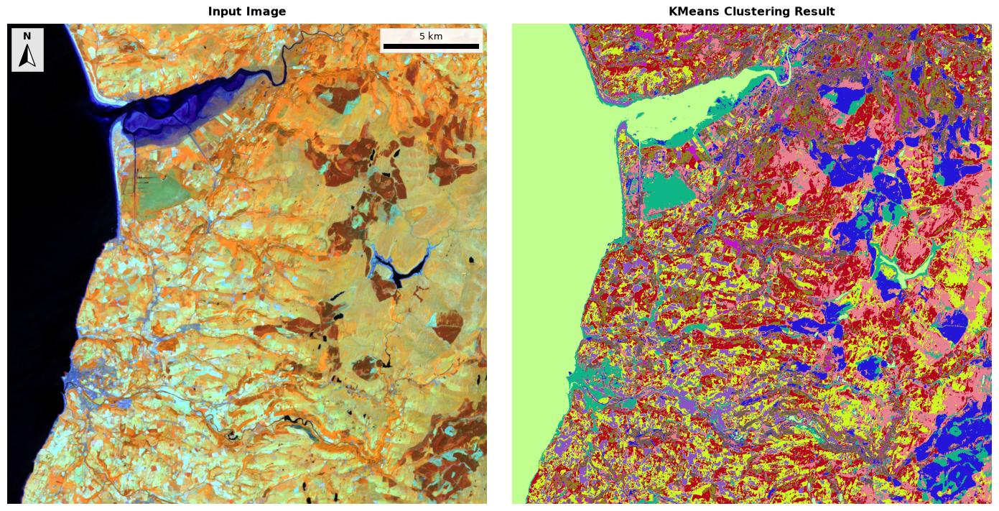

In [4]:
# Define a bbox (xmin, xmax, ymin, ymax) for the subset to be displayed
# sub_img_bbox = [275000, 300000, 275000, 300000]
sub_img_bbox = [255000, 280000, 275000, 300000]
# sub_img_bbox = [295000, 300000, 295000, 300000]

fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", kmeans_cls_img, title="KMeans Clustering Result"),
    ],
    bbox=sub_img_bbox,
    show_legend=False,
    figsize=(14, 7),
)

# 5. Apply Mean-Shift clusterer

Information on Mean-Shift: https://scikit-learn.org/stable/modules/clustering.html#mean-shift

Mean-shift does not need the number of clusters; instead it needs a *bandwidth* (the size of the region in feature space used to find each cluster's centre). With `clusterer=None` and `use_mean_shift_est_band_width=True`, the bandwidth is estimated from the sampled pixels with scikit-learn's `estimate_bandwidth`, where `mean_shift_quantile` controls the size of the neighbourhood used: a smaller value gives a smaller bandwidth and therefore more clusters.

Mean-shift is slow for many samples, so the sample is capped at 10,000 pixels (`max_samples`).

In [5]:
meanshift_cls_img = os.path.join(out_dir, "sen2_20180629_meanshift_cls.tif")
ms_model = img_pixel_sample_cluster(
    img_band_info,
    meanshift_cls_img,
    clusterer=None,
    n_img_smpl=100,
    max_samples=10000,
    no_data_val=0,
    use_mean_shift_est_band_width=True,
    mean_shift_quantile=0.1,
    calc_stats=True,
    rnd_seed=42,
    return_model=True,  # return the fitted clusterer
    use_pbar=False,
)
print(ms_model)
print(f"Number of clusters: {len(ms_model.cluster_centers_)}")

MeanShift(bandwidth=97.07460770714269, bin_seeding=True)
Number of clusters: 9


# 6. Visualise Mean-Shift result

Note, the assigned colours are random. Try looking at some different areas by editing `sub_img_bbox`, and try changing `mean_shift_quantile` (e.g., 0.05 or 0.3) to see how the number of clusters changes.

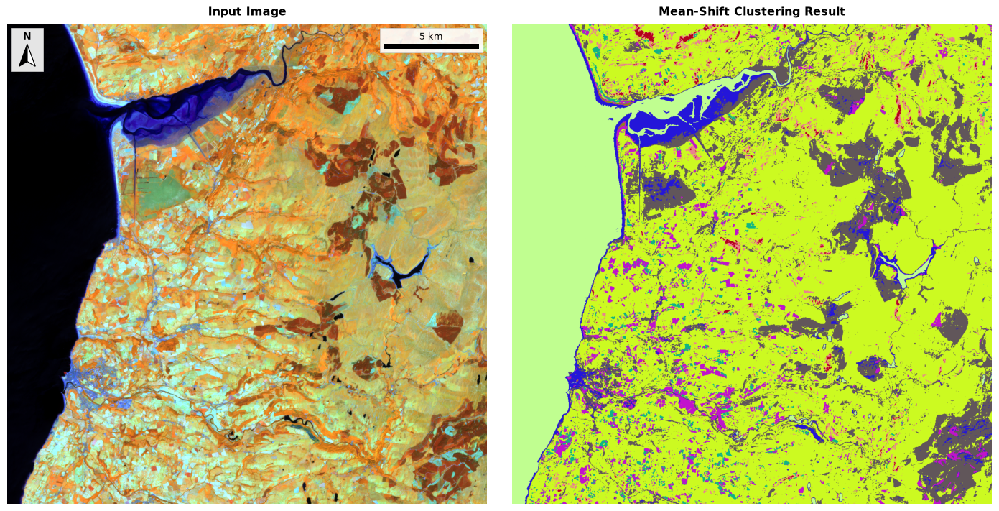

In [6]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", meanshift_cls_img, title="Mean-Shift Clustering Result"),
    ],
    bbox=sub_img_bbox,
    show_legend=False,
    figsize=(14, 7),
)

# 7. Cluster centres and other clustering algorithms

The clusters are defined by their *centres*: the mean value of each band for the pixels in the cluster. Each pixel is given the cluster with the nearest centre. Looking at the centres (e.g., as spectra) helps to decide what each cluster represents.

> **RSGISLib users:** RSGISLib had its own K-means and ISODATA implementations (`imagecalc.kmeans_clustering` and `imagecalc.isodata_clustering`), which wrote the cluster centres to a file that was then applied with `segmentation.label_pixels_from_cluster_centres`. In rsgispy, any scikit-learn clusterer is fitted on a sample and applied in one call with `img_pixel_sample_cluster`; the fitted clusterer (with its centres) can be returned (`return_model=True`) or saved to a file (`out_model_file`), and applied to other images with `apply_img_pixel_clusterer` (section 8). There is no ISODATA algorithm in scikit-learn or rsgispy; bisecting K-means (section 7.2) is used here instead.

## 7.1 KMeans

The full K-means algorithm (rather than the mini-batch version used above) is fitted on the sample, with up to 200 iterations. The fitted model is returned and also saved to a file, so it can be applied to another image later (section 8) or reloaded with `joblib.load`.

In [7]:
from sklearn.cluster import KMeans

kmeans_full_cls_img = os.path.join(out_dir, "sen2_20180629_kmeans_full_cls.tif")
kmeans_model = img_pixel_sample_cluster(
    img_band_info,
    kmeans_full_cls_img,
    clusterer=KMeans(n_clusters=10, max_iter=200, n_init=10, random_state=42),
    n_img_smpl=100,
    no_data_val=0,
    rnd_seed=42,
    out_model_file=os.path.join(out_dir, "kmeans_model.joblib"),
    return_model=True,
    use_pbar=False,
)

The cluster centres as a table (one row per cluster, numbered as in the output image):

In [8]:
centres_df = pandas.DataFrame(
    kmeans_model.cluster_centers_,
    columns=band_names,
    index=pandas.Index(range(1, len(kmeans_model.cluster_centers_) + 1), name="Cluster"),
)
centres_df.round(1)

,Blue,Green,Red,RE_B5,RE_B6,RE_B7,NIR_B8,NIR_B8A,SWIR1,SWIR2
Cluster,,,,,,,,,,
1,34.7,25.5,9.3,9.7,9.8,9.5,8.6,8.0,4.8,5.0
2,39.3,73.3,43.3,137.7,434.5,521.6,555.4,577.4,276.6,130.1
3,30.7,51.2,29.0,93.6,309.5,368.6,381.6,401.1,166.7,76.1
4,76.1,109.6,134.0,208.3,330.1,375.2,407.8,439.4,412.9,257.1
5,33.8,59.9,34.9,114.2,379.9,457.0,480.2,503.5,232.7,107.7
6,58.1,78.8,80.0,139.5,262.0,295.4,308.2,332.4,278.5,170.0
7,47.8,81.0,65.4,156.8,384.6,450.7,483.0,509.1,326.5,168.0
8,30.9,45.9,30.4,78.7,230.7,270.7,276.6,291.9,125.4,60.6
9,37.0,73.1,35.6,134.1,503.1,614.0,651.4,666.9,262.7,118.5


Plotting the centres as spectra makes it easier to see what they are: e.g., vegetation has a high near infrared (NIR) reflectance, while water is low in all bands.

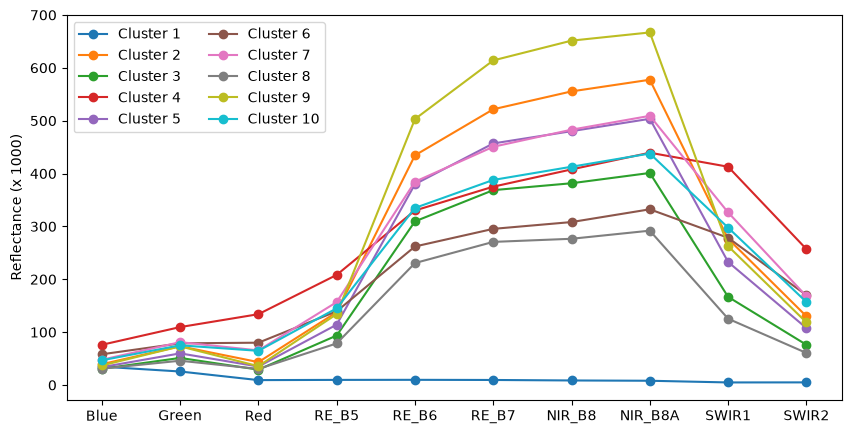

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
for clu_id, centre in centres_df.iterrows():
    ax.plot(band_names, centre.values, marker="o", label=f"Cluster {clu_id}")
ax.set_ylabel("Reflectance (x 1000)")
ax.legend(ncol=2)
plt.show()

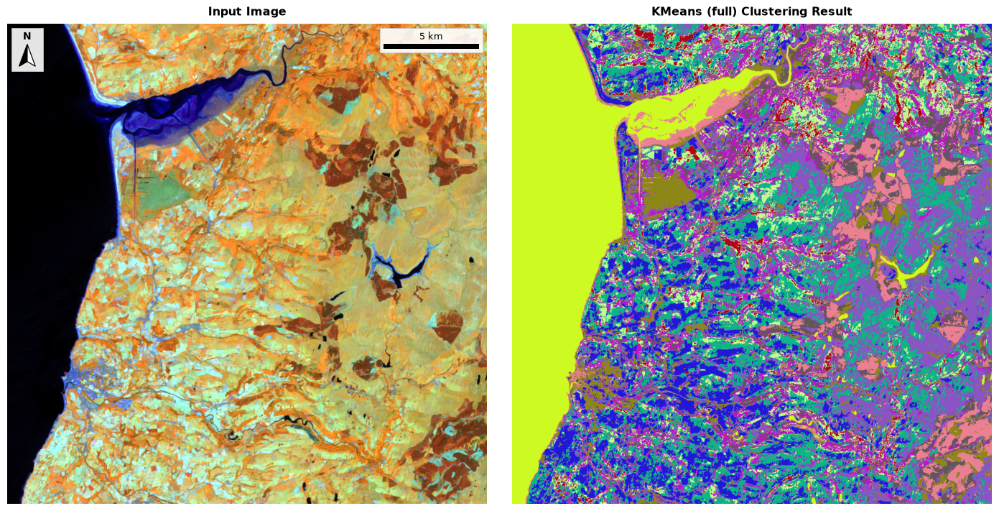

In [10]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", kmeans_full_cls_img, title="KMeans (full) Clustering Result"),
    ],
    bbox=sub_img_bbox,
    show_legend=False,
    figsize=(14, 7),
)

## 7.2 Bisecting KMeans (instead of ISODATA)

ISODATA is a variant of K-means which splits clusters that are too spread out and merges clusters that are too close. scikit-learn's [bisecting K-means](https://scikit-learn.org/stable/modules/clustering.html#bisect-k-means) also builds the clusters by splitting: it starts with one cluster and repeatedly splits a cluster in two (by default the one with the largest spread) until there are `n_clusters`.

In [11]:
from sklearn.cluster import BisectingKMeans

bkmeans_cls_img = os.path.join(out_dir, "sen2_20180629_bisect_kmeans_cls.tif")
img_pixel_sample_cluster(
    img_band_info,
    bkmeans_cls_img,
    clusterer=BisectingKMeans(n_clusters=10, random_state=42),
    n_img_smpl=100,
    no_data_val=0,
    rnd_seed=42,
    use_pbar=False,
)

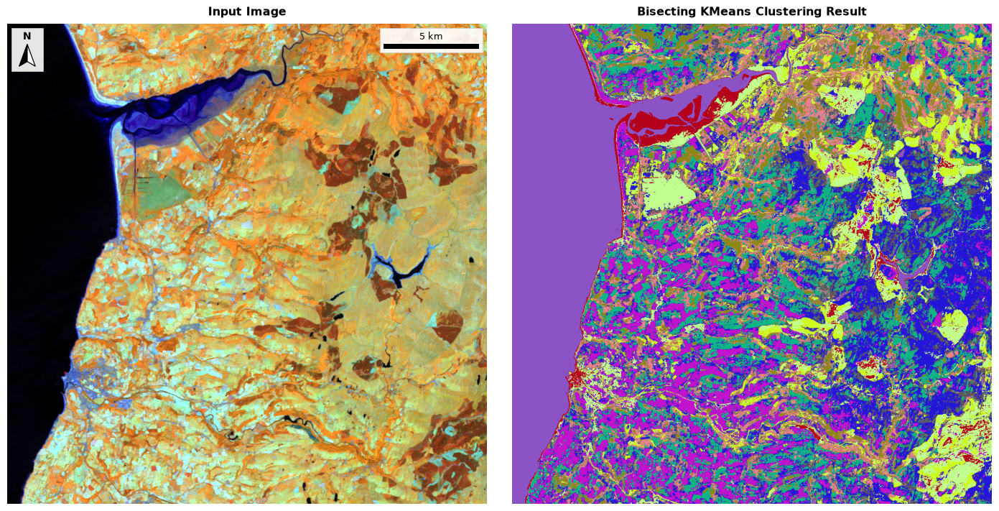

In [12]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", bkmeans_cls_img, title="Bisecting KMeans Clustering Result"),
    ],
    bbox=sub_img_bbox,
    show_legend=False,
    figsize=(14, 7),
)

How do the clusterings compare? Which clusters would you merge to make land cover classes, and which classes are mixed up in one cluster? This is the main limitation of unsupervised classification: the clusters are groups in the data, which are not necessarily the classes you are interested in.

# 8. Apply the fitted clusterer to another image

The clusterers above were fitted on a sample of one image and then applied to all its pixels. A fitted clusterer can also be applied to another image with `apply_img_pixel_clusterer`, as long as that image has the same bands, in the same order, with the same scaling. The clusters then mean the same thing in both outputs (cluster 3 has the same centre in both), which is not the case if each image is clustered on its own: K-means numbers its clusters arbitrarily, so a second clustering would give different cluster IDs, and different centres, for the same land covers.

Here the full K-means clusterer of section 7.1, saved to `kmeans_model.joblib`, is applied to a Sentinel-2 image of Aberystwyth from 27 May 2021. It has the same 10 bands, scaled the same way (reflectance x 1000), but 10 m pixels (the 20 m bands were resampled) and it covers a smaller area. The clusterer works pixel by pixel, so the pixel size does not matter.

In [13]:
input_2021_img = "../data/sen2_20210527_aber.tif"
print(get_band_names(input_2021_img) == band_names)

kmeans_2021_cls_img = os.path.join(out_dir, "sen2_20210527_kmeans_full_cls.tif")
apply_img_pixel_clusterer(
    input_2021_img,
    os.path.join(out_dir, "kmeans_model.joblib"),  # or the fitted kmeans_model
    kmeans_2021_cls_img,
    no_data_val=0,
    use_pbar=False,
)

# The colour tables are random: give the 2021 clusters the colours of the
# 2018 clusters, so the same cluster has the same colour in both maps.
clrs_2018 = get_colour_tab_info(kmeans_full_cls_img)
define_colour_table(
    kmeans_2021_cls_img,
    {val: (c["red"], c["green"], c["blue"]) for val, c in clrs_2018.items() if val > 0},
)

True


The two clusterings over the area of the 2021 image (the 2021 image is shown, as an `'rgb'` panel):

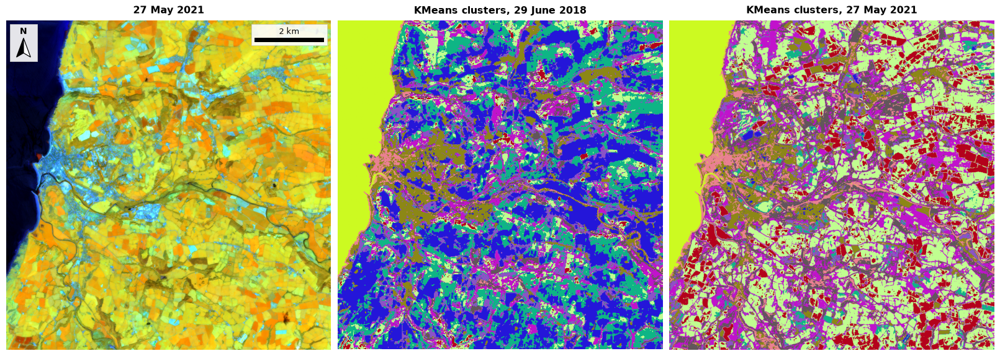

In [14]:
# The extent of the 2021 image (xmin, xmax, ymin, ymax).
aber_bbox = list(get_img_bbox(input_2021_img))[:4]

fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_2021_img, bands=[8, 9, 3], title="27 May 2021"),
        map_layout.MapPanel("thematic", kmeans_full_cls_img, title="KMeans clusters, 29 June 2018"),
        map_layout.MapPanel("thematic", kmeans_2021_cls_img, title="KMeans clusters, 27 May 2021"),
    ],
    bbox=aber_bbox,
    show_legend=False,
    figsize=(16, 6),
)

As the cluster IDs mean the same thing, the proportion of the area in each cluster can be compared between the two dates (for the 2018 image, only the pixels within the extent of the 2021 image are counted):

In [15]:
def cluster_pcts(cls_img, bbox):
    """The percentage of the valid pixels of cls_img within bbox
    (xmin, xmax, ymin, ymax) in each cluster."""
    with rasterio.open(cls_img) as ds:
        win = rasterio.windows.from_bounds(bbox[0], bbox[2], bbox[1], bbox[3], ds.transform)
        arr = ds.read(1, window=win.round_offsets().round_lengths())
    counts = numpy.bincount(arr[arr > 0], minlength=len(centres_df) + 1)[1:]
    return 100 * counts / counts.sum()


clu_pcts_df = pandas.DataFrame(
    {
        "2018 (%)": cluster_pcts(kmeans_full_cls_img, aber_bbox),
        "2021 (%)": cluster_pcts(kmeans_2021_cls_img, aber_bbox),
    },
    index=centres_df.index,
)
clu_pcts_df.round(1)

,2018 (%),2021 (%)
Cluster,,
1,9.3,9.3
2,7.5,30.2
3,3.0,11.5
4,26.7,0.4
5,8.9,18.6
6,8.1,7.7
7,21.6,2.3
8,1.4,4.6
9,1.0,10.3


The sea (cluster 1, low reflectance in every band) covers the same proportion of the area on both dates, but the land clusters have changed a lot. In June 2018 over a quarter of the area was in cluster 4, the cluster with the highest red and SWIR reflectance of the vegetated clusters (look back at the cluster centres), and much of the rest in cluster 7; in May 2021 most of the land is in clusters 2, 3, 5 and 9, which have a higher near infrared and a lower SWIR reflectance: green, well watered vegetation. The summer of 2018 was very hot and dry in the UK, and by the end of June much of the grassland had dried out, whereas in May 2021 the grass was growing. So applying one clusterer to both dates shows where, and how much, the land surface changed between the images, which separate clusterings could not show directly.

Remember that the clusters are groups of reflectance values, not land covers: a field in cluster 4 in 2018 and cluster 9 in 2021 is probably the same grassland, just drier. This also only works when the images are comparable: the same bands, the same processing (here both are surface reflectance) and the same scaling. Applied to an image from another sensor, or top-of-atmosphere reflectance, the clusters would shift for reasons which have nothing to do with the land surface.

In the next notebook we will use training data to learn the classes we want (supervised classification).